# Question 1 (18 pts) 
We will look into the NYC flights dataset using Pandas!

## Question 1.1 (2 pts)
Load the dataset from flights.csv file given with this file into a dataframe variable named `df`

In [1]:
import pandas as pd
df = pd.read_csv("flights.csv.gz")

In [2]:
assert df is not None
assert isinstance(df, pd.core.frame.DataFrame)

## Question 1.2 (2 pts)
Get the total count of flights for each month and display the top three months with the highest count.

In [3]:
# count flights per month, then keep the 3 largest
monthly_count = df['month'].value_counts().head(3)
monthly_count

month
7     29425
8     29327
10    28889
Name: count, dtype: int64

In [4]:
assert all(monthly_count == pd.Series([29425, 29327, 28889], index = [7, 8, 10]))

## Question 1.3 (2 pts)
First get a new dataframe with the three columns of interest 'carrier', 'month' and 'dep_delay'. Then compute the average dep_delay for each carrier and for each month. Rank the departure delays/month and filter the 1st rank carrier for each month (carrier with the lowest dep_delay for the month will get the 1st rank). Show the results in ascending order of the month

Hint: Some of the functions that can help are rank(), unstack(), stack(). 

In [5]:
# keep only the three columns we need
delay_df = df[['carrier', 'month', 'dep_delay']]

# average dep_delay for every (month, carrier) pair -> months as rows, carriers as columns
avg_by_month = delay_df.groupby(['month', 'carrier'])['dep_delay'].mean().unstack()

# rank carriers within each month (lowest average delay = rank 1)
ranks = avg_by_month.rank(axis=1, method='min')

# back to long form and keep only the 1st-ranked carrier per month
avg_delay = (avg_by_month.stack().to_frame('avg_dep_delay')
             .join(ranks.stack().to_frame('rank')))
avg_delay = avg_delay[avg_delay['rank'] == 1].reset_index().sort_values('month')
avg_delay

,month,carrier,avg_dep_delay,rank
0,1,VX,1.063492,1.0
1,2,AS,0.722222,1.0
2,3,HA,1.161290,1.0
3,4,HA,-2.100000,1.0
4,5,HA,-1.451613,1.0
5,6,HA,1.466667,1.0
6,7,HA,-1.709677,1.0
7,8,HA,1.677419,1.0
8,9,HA,-5.440000,1.0
9,10,HA,-5.095238,1.0


In [6]:
# Hidden test here

## Question 1.4 (2 pts)
Find the 5 top destinations in this dataset (most number of flights to). Filter only those flights to these top 5 destinations and then show the distribution of carriers on this filtered data.

In [7]:
# 5 destinations with the most flights
top_dest = df['dest'].value_counts().head(5).index.values

# keep only flights to those destinations and count flights per carrier
top_flights = df[df['dest'].isin(top_dest)]
top_carrier_count = top_flights['carrier'].value_counts()
print(top_dest)
top_carrier_count

['ORD' 'ATL' 'LAX' 'BOS' 'MCO']


carrier
UA    19469
DL    17707
B6    13448
AA    11826
MQ     4598
US     4283
VX     2580
FL     2337
9E     2029
EV     1925
WN       59
OO        1
Name: count, dtype: int64

In [8]:
import numpy as np
assert np.all(top_dest == np.array(['ORD', 'ATL', 'LAX', 'BOS', 'MCO']))

## Question 1.5 (2 pts)
Get the total count of cancelled flights in this dataset. We'll say that a cancelled flight has dep_time missing.

In [9]:
# a cancelled flight has a missing dep_time
cancelled_flight_count = df['dep_time'].isna().sum()
cancelled_flight_count

np.int64(8255)

In [10]:
assert cancelled_flight_count == 8255

## Question 1.6 (2 pts)
Count all the destinations that have a letter 'K' anywhere in the name code.

In [11]:
# count flights whose destination code contains the letter K
dest_with_k = df['dest'].str.contains('K').sum()
dest_with_k

np.int64(4589)

In [12]:
assert dest_with_k == 4589

## Question 1.7 (2 pts)
Create a new column called speed that computes the speed as distance/air_time

In [13]:
df['speed'] = df['distance'] / df['air_time']
df['speed'].head()

0    6.167401
1    6.237885
2    6.806250
3    8.612022
4    6.568966
Name: speed, dtype: float64

In [14]:
assert type(df['speed']) == pd.Series 
assert abs(df['speed'][0] - 6.1674) < 1

## Question 1.8 (4 pts)
Segment the dep_time 24 hours into 
* night from 12 midnight to 5 am
* morning from 5:01 am to 12 noon
* afternoon from 12.01 noon to 5 pm
* evening from 5.01 pm to 12 am

And then run a query to find the total flights in each segment and save that value in the given variable.


In [15]:
# dep_time is stored as hhmm (e.g. 517 = 5:17 am, 2400 = midnight)
bins = [0, 500, 1200, 1700, 2400]
labels = ['night', 'morning', 'afternoon', 'evening']
df['part_of_day'] = pd.cut(df['dep_time'], bins=bins, labels=labels, include_lowest=True)

# count the flights in each segment
parts_of_day_count = df['part_of_day'].value_counts()
parts_of_day_count

part_of_day
morning      129939
afternoon     98733
evening       98362
night          1487
Name: count, dtype: int64

In [16]:
assert parts_of_day_count['morning'] == 129939
assert parts_of_day_count['evening'] == 98362

# Question 2 (9 pts) 
In this problem, we will do some exploratory data analytics (EDA) by using some of the visualization libraries in Python.

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
flights = pd.read_csv("flights.csv.gz")
#airports = pd.read_csv("airports.csv")
#the above .csv file was not provided. Commenting out to avoid error.
flights.describe()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,flight,air_time,distance,hour,minute
count,336776.0,336776.000000,336776.000000,328521.000000,336776.000000,328521.000000,328063.000000,336776.000000,327346.000000,336776.000000,327346.000000,336776.000000,336776.000000,336776.000000
mean,2013.0,6.548510,15.710787,1349.109947,1344.254840,12.639070,1502.054999,1536.380220,6.895377,1971.923620,150.686460,1039.912604,13.180247,26.230100
std,0.0,3.414457,8.768607,488.281791,467.335756,40.210061,533.264132,497.457142,44.633292,1632.471938,93.688305,733.233033,4.661316,19.300846
min,2013.0,1.000000,1.000000,1.000000,106.000000,-43.000000,1.000000,1.000000,-86.000000,1.000000,20.000000,17.000000,1.000000,0.000000
25%,2013.0,4.000000,8.000000,907.000000,906.000000,-5.000000,1104.000000,1124.000000,-17.000000,553.000000,82.000000,502.000000,9.000000,8.000000
50%,2013.0,7.000000,16.000000,1401.000000,1359.000000,-2.000000,1535.000000,1556.000000,-5.000000,1496.000000,129.000000,872.000000,13.000000,29.000000
75%,2013.0,10.000000,23.000000,1744.000000,1729.000000,11.000000,1940.000000,1945.000000,14.000000,3465.000000,192.000000,1389.000000,17.000000,44.000000
max,2013.0,12.000000,31.000000,2400.000000,2359.000000,1301.000000,2400.000000,2359.000000,1272.000000,8500.000000,695.000000,4983.000000,23.000000,59.000000


## Question 2.1 (3 pts)

Line charts are ideal to show a trend line. Draw a line chart to show monthly frequency count of flights as a trend line for the year 2013. Be sure to choose the correct data to display on the x-axis and y-axis.

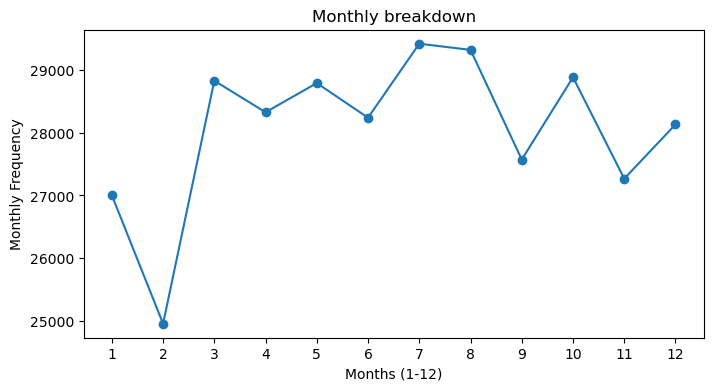

In [18]:
import matplotlib.pyplot as plt

# number of flights in each month, in month order 1-12
monthly = flights['month'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, marker='o')
ax.set_title('Monthly breakdown')
ax.set_xlabel('Months (1-12)')
ax.set_ylabel('Monthly Frequency')
ax.set_xticks(range(1, 13))
fig1 = ax

In [19]:
assert fig1.get_title() == 'Monthly breakdown'
assert fig1.get_xlabel() == 'Months (1-12)'
assert fig1.get_ylabel() == 'Monthly Frequency'
assert dict(fig1.lines[0].get_xydata())[6] == 28243

## Question 2.2 (3 pts)
Show the top 5 airports that people flew into using a bar chart. 

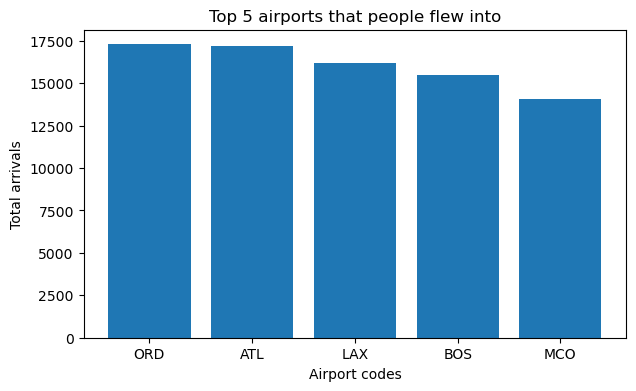

In [20]:
# 5 destinations with the most arrivals
top5 = flights['dest'].value_counts().head(5)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(top5.index, top5.values)
ax.set_title('Top 5 airports that people flew into')
ax.set_xlabel('Airport codes')
ax.set_ylabel('Total arrivals')
fig2 = ax
fig_2 = ax   # the test cell below uses the name fig_2

In [21]:
x_axis = fig_2.get_xaxis()
text1 = x_axis.get_ticklabels()[0]
assert text1.get_text() == 'ORD'
assert fig_2.get_title() == 'Top 5 airports that people flew into'
assert fig_2.get_xlabel() == 'Airport codes'
assert fig_2.get_ylabel() == 'Total arrivals'

## Question 2.3 (3 pts)

Segment the flights based on time-slots with the following criteria
* flights that depart from 00-5:59am as 'red-eye' flights
* flights that depart from 6am - 11:59am as 'morning'
* flights that depart from 12noon - 3:59pm as 'afternoon'
* flights that depart from 4pm - 11:59pm as 'evening' 

And using seaborn create a plot as shown below. PS: Feel free to choose your color palette.

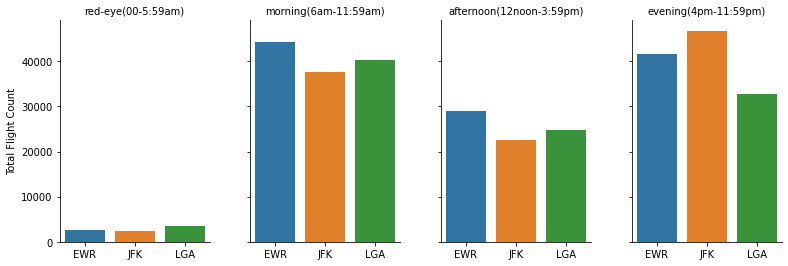

/var/folders/44/2qc98bts56x7nrd5lhtrhp5c0000gn/T/ipykernel_16754/619752028.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  fig_3 = sns.catplot(data=flights.dropna(subset=['time_slot']), x='origin', kind='count',


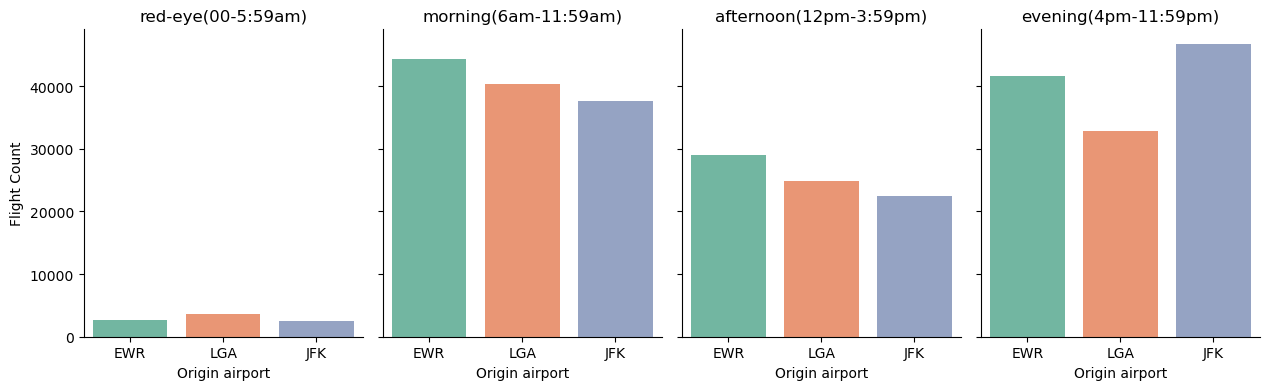

In [22]:
# label each flight by its departure time slot (dep_time is hhmm)
def time_slot(t):
    if pd.isna(t):
        return None          # cancelled flight, no departure
    t = int(t) % 2400        # treat 2400 as 00:00
    if t < 600:
        return 'red-eye'
    elif t < 1200:
        return 'morning'
    elif t < 1600:
        return 'afternoon'
    else:
        return 'evening'

flights['time_slot'] = flights['dep_time'].apply(time_slot)

order = ['red-eye', 'morning', 'afternoon', 'evening']
titles = ['red-eye(00-5:59am)', 'morning(6am-11:59am)',
          'afternoon(12pm-3:59pm)', 'evening(4pm-11:59pm)']

# one count plot of flights by origin airport for each time slot
fig_3 = sns.catplot(data=flights.dropna(subset=['time_slot']), x='origin', kind='count',
                    col='time_slot', col_order=order, palette='Set2', height=4, aspect=0.8)
for ax, title in zip(fig_3.axes.flat, titles):
    ax.set_title(title)
fig_3.set_axis_labels('Origin airport', 'Flight Count')

In [23]:
assert fig_3.figure.get_axes()[0].get_title() == 'red-eye(00-5:59am)'
assert fig_3.figure.get_axes()[0].get_ylabel() == 'Flight Count'
assert fig_3.figure.get_axes()[1].get_title() == 'morning(6am-11:59am)'